In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/cleaned-off/off_filtered.csv


In [2]:
!pip install -q easyocr rapidfuzz                                 # EasyOCR = reads text in pictures; rapidfuzz = text similarity

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 36.0 MB/s eta 0:00:0000:0100:01


In [3]:
import pandas as pd                                               # tables
import requests                                                   # internet requests
import time                                                       # pauses between requests

off_path = "/kaggle/input/cleaned-off/off_filtered.csv"                      # English OFF, same file as before
off = pd.read_csv(off_path, dtype={"code": str})                  # load; barcodes as text
picked = off.sample(160, random_state=42).reset_index(drop=True)   # 60 random products, repeatable

headers = {"User-Agent": "FoodScanner student project (university coursework)"}  # tell OFF who we are
fields = "image_ingredients_url,image_nutrition_url"              # the two photo links we want

ingr_urls, nutr_urls = [], []                                     # lists to fill, one entry per product
for code in picked["code"]:                                       # go through the 60 barcodes
    url = f"https://world.openfoodfacts.org/api/v2/product/{code}?fields={fields}"  # API address for this product
    try:                                                          # try; skip on errors
        data = requests.get(url, headers=headers, timeout=10).json()  # ask OFF, read the answer as a dictionary
        product = data.get("product", {})                         # the product part (empty if not found)
        ingr_urls.append(product.get("image_ingredients_url"))    # ingredients photo link, or None
        nutr_urls.append(product.get("image_nutrition_url"))      # nutrition photo link, or None
    except Exception:                                             # network error
        ingr_urls.append(None)                                    # mark as missing
        nutr_urls.append(None)                                    # mark as missing
    time.sleep(0.7)                                               # be polite: OFF allows ~100 product requests per minute

picked["ingr_url"] = ingr_urls                                    # add the links as new columns
picked["nutr_url"] = nutr_urls                                    # same for nutrition photos
print(picked["ingr_url"].notna().sum(), "have an ingredients photo")  # how many of 60
print(picked["nutr_url"].notna().sum(), "have a nutrition photo")     # how many of 60

42 have an ingredients photo
49 have a nutrition photo


In [4]:
import torch                                      # PyTorch (EasyOCR runs on it)
print(torch.cuda.is_available())                  # True = GPU is on

True


PRODUCT: Sausage Roll 100% British Pork
OCR:     EmcazE0 - GoLDc" bake DEL Dol7ev Icdeu_ EAUSAGED 1 1 1
OFF:     British pork (29%), wheat flour (calcium carbonate, iron, niacin, thiamin), pork fat, vegetable oil (palm, rapeseed), water, egg, salt, potato starch, milk, spices, herbs, mustard


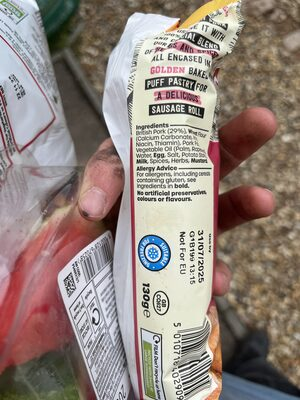

In [5]:
import easyocr                                                    # the OCR library
import numpy as np                                                # EasyOCR wants pictures as number arrays
from io import BytesIO                                            # downloaded bytes -> file in memory
from PIL import Image                                             # open pictures

reader = easyocr.Reader(["en"], gpu=True)                         # load the English reading model (downloads ~100 MB once), CPU

with_ingr = picked[picked["ingr_url"].notna()].reset_index(drop=True)  # only products that have an ingredients photo
row = with_ingr.loc[0]                                             # take the first one
r = requests.get(row["ingr_url"], headers=headers, timeout=10)     # download its ingredients photo
img = Image.open(BytesIO(r.content)).convert("RGB")                # bytes -> picture

lines = reader.readtext(np.array(img), detail=0, paragraph=True)   # read the text; detail=0 = text only; paragraph=True = join nearby words
ocr_text = " ".join(lines)                                         # glue the pieces into one string

print("PRODUCT:", row["product_name"])                             # which product
print("OCR:    ", ocr_text[:400])                                  # what EasyOCR read (first 400 characters)
print("OFF:    ", str(row["ingredients_text"])[:400])              # the correct text typed into OFF
img                                                                # show the photo

In [6]:
print(row["ingr_url"])                                           # look at the link: does it end in .400.jpg?
full_url = row["ingr_url"].replace(".400.", ".full.")            # ask for the full-resolution version instead
r = requests.get(full_url, headers=headers, timeout=10)          # download it
img_full = Image.open(BytesIO(r.content)).convert("RGB")         # bytes -> picture
print(img.size, "->", img_full.size)                             # small size vs full size in pixels

lines = reader.readtext(np.array(img_full), detail=0, paragraph=True,
                        rotation_info=[90, 270])                 # also try the picture turned 90 and 270 degrees
print("OCR full:", " ".join(lines)[:400])                        # what it reads now

https://images.openfoodfacts.org/images/products/501/071/840/2909/ingredients_en.29.400.jpg
(300, 400) -> (3024, 4032)
OCR full: W IT CK 1 USL AmD P WITh OUR 0 ES 4 BLENO Of Ke 0 9 ALL ENGASED IM GOLDEN BAKE PUFF PASTRY 3 DELICIOUS  SAUSAGE ROLL; Ingredients British Pork (29%) 4 (Calcium Carbonate k Flour Niacin Thiamin) Pork Fa Vegetable Qil (Palm 2 1 1 Allergy Advice For allergens; including cereals containing gluten see ingredients in bold: No artificial preservatives; colours or flavours: 02 # 22 6 8 Not "85202982L0004 


In [7]:
import re                                                        # regular expressions, for cleaning text

def read_ingredients(url):                                       # photo link -> OCR text of the ingredient list
    full_url = url.replace(".400.", ".full.")                    # full-resolution version
    r = requests.get(full_url, headers=headers, timeout=20)      # download it
    img = Image.open(BytesIO(r.content)).convert("RGB")          # bytes -> picture
    lines = reader.readtext(np.array(img), detail=0, paragraph=True, rotation_info=[90, 270])  # read, allow sideways text
    text = " ".join(lines)                                       # one string
    pos = text.lower().find("ingredient")                        # where does the word "ingredient(s)" start? (-1 if absent)
    if pos >= 0:                                                 # if found...
        text = text[pos:]                                        # ...keep only the text from there on
    return text                                                  # the cleaned OCR text

def words(text):                                                 # text -> set of lowercase words of 3+ letters
    return set(re.findall(r"[a-z]{3,}", str(text).lower()))      # e.g. "Pork Fat, Egg" -> {"pork", "fat", "egg"}

def word_recall(ocr_text, off_text):                             # share of OFF's words that OCR also found
    truth = words(off_text)                                      # the correct words
    if not truth:                                                # avoid dividing by zero
        return None                                              # no score possible
    return len(truth & words(ocr_text)) / len(truth)             # & = words in both sets; divide by number of correct words

t0 = time.time()                                                 # start clock
ocr0 = read_ingredients(row["ingr_url"])                         # the sausage roll again, with the new function
print(round(time.time() - t0), "s")                              # how long one photo takes
print(ocr0[:300])                                                # should now start at "Ingredients"
print("word recall:", round(word_recall(ocr0, row["ingredients_text"]), 2))  # share of correct words found

8 s
Ingredients British Pork (29%) 4 (Calcium Carbonate k Flour Niacin Thiamin) Pork Fa Vegetable Qil (Palm 2 1 1 Allergy Advice For allergens; including cereals containing gluten see ingredients in bold: No artificial preservatives; colours or flavours: 02 # 22 6 8 Not "85202982L0004 1 1 ( ) For 31/07/
word recall: 0.39


In [8]:
results = []                                                     # one entry per product
for i, row in with_ingr.iterrows():                              # go through every product with an ingredients photo
    try:                                                         # safety net
        text = read_ingredients(row["ingr_url"])                 # OCR the full-size photo
    except Exception:                                            # download/reading problem
        text = None                                              # mark as failed
    rec = word_recall(text, row["ingredients_text"]) if text else None  # score, or None if it failed
    results.append({"code": row["code"],                         # barcode
                    "product_name": row["product_name"],         # name
                    "ocr_text": text,                            # what OCR read
                    "off_text": row["ingredients_text"],         # the correct text
                    "recall": rec})                              # share of correct words found
    print(i, "failed" if rec is None else round(rec, 2), str(row["product_name"])[:40])  # progress line

ingr_dev = pd.DataFrame(results)                                 # list -> table
ingr_dev.to_csv("ocr_ingredients_dev.csv", index=False)          # save it
print(ingr_dev["recall"].describe().round(2))                    # count, mean, median (50%), min, max

0 0.39 Sausage Roll 100% British Pork
1 0.88 Raw Brazil Nuts
2 0.6 Fairtrade Unrefined Demerara Pure Cane S
3 0.6 British Red Leicester
4 0.12 TIRAMISU FLAVOUR
5 1.0 Peppered Hot Smoked Salmon Fillets
6 0.5 Sliced Green Jalapeño Peppers
7 1.0 Extra Virgin Olive Oil
8 0.67 Wheat & Rye Sourdough Bread
9 0.96 Crispy M&Ms
10 1.0 Hickory & Oak Wood Scottish Smoked Salmo
11 0.97 Cherry & amaretto stollen slices
12 0.67 Whole grain health bread
13 0.66 Flautas Chicken & Cheese
14 1.0 bay leaves
15 0.0 Thai Yellow Curry Paste
16 1.0 back bacon
17 0.5 Reduced Fat Creamy Caesar Dressing
18 0.72 crispy chicken goujons
19 1.0 Wholemeal Bread
20 0.9 White linen marinara sauce
21 0.58 ORGANIC SOFT BAKED OAT BARS cinnamon bun
22 0.0 Bière
23 0.0 Sushi Rice
24 0.68 Immunitea Vit hit Immunitea Dragon Fruit
25 0.95 Fizzy Cola Langes
26 0.86 Shreddies
27 0.96 Mayo Korean Gochujang
28 0.35 Slonecznik
29 0.01 Hoisin Sauce
30 0.46 Nut selection hazelnut
31 1.0 Maizena Fleur de Maïs Sans Gluten 400g
32 0.67 

In [9]:
low = ingr_dev[ingr_dev["recall"] < 0.2]                         # the badly read photos
for _, r in low.iterrows():                                      # go through each one
    print("PRODUCT:", r["product_name"], "| recall", round(r["recall"], 2))  # which product
    print("  OCR:", str(r["ocr_text"])[:150])                    # start of what OCR kept
    print("  OFF:", str(r["off_text"])[:150])                    # start of the correct text
    print()                                                      # blank line between products

PRODUCT: TIRAMISU FLAVOUR | recall 0.12
  OCR: ingredients in BOLD. Contains a 0 ource of Phenytalanne NRVIs 1 2 1 8 Nurient Reference Value:
  OFF: yogurt (milk), water, modified maize starch, flavouring, sweetener: aspar - leyde tame, colour: plain caramel, salt, stabiliser pectin, acidity regula

PRODUCT: Thai Yellow Curry Paste | recall 0.0
  OCR: 4 2 1 -lngredients _ Fesh_ GairHc Redchulp 1 1 3 NUTRITIONAL VALUES (10Og] Energy: 820kJ 196kca 2 2 of which saturates. : 3 of which trans fats. Og 6 
  OFF: Fresh Gartic, Red chil Lemongrass, Galangat, Salt, Shallots, Jurmeric Rice Bran Oil, Cumin, Black Pepper Coriander Seeds

PRODUCT: Bière | recall 0.0
  OCR: Ingredients : Water; Malted Barley; 3 Yeast  Contains 2 Barley
  OFF: Eau, Malt d'orge, Houblons, Levure.

PRODUCT: Sushi Rice | recall 0.0
  OCR: 1
  OFF: Sushi rice.

PRODUCT: Hoisin Sauce | recall 0.01
  OCR: 1 1 Shewelbeldeue 1 3 2 L [ 3 L Gmel( 4 3 L MLERO 0 0 [ 2 1 artifdal 3 [ 1 1 Thisbotec 0 I 8 0 4 5 5 1 8 1 4 1 3 0 1 0 

In [10]:
def read_ingredients(url):                                       # photo link -> OCR text of the ingredient list
    full_url = url.replace(".400.", ".full.")                    # full-resolution version
    r = requests.get(full_url, headers=headers, timeout=20)      # download it
    img = Image.open(BytesIO(r.content)).convert("RGB")          # bytes -> picture
    lines = reader.readtext(np.array(img), detail=0, paragraph=True,
                            rotation_info=[90, 270])        # NEW: also try upside down
    text = " ".join(lines)                                       # one string
    low = text.lower()                                           # lowercase copy for searching
    starts = [m.start() for m in re.finditer(r"ingredient", low)]  # every position where "ingredient" appears
    good = [p for p in starts if "in bold" not in low[p:p + 25]]   # NEW: skip "ingredients in bold" (allergy advice)
    if good:                                                     # if a real heading was found...
        text = text[good[0]:]                                    # ...keep the text from the first one on
    return text                                                  # otherwise keep everything

In [11]:
def words(text):                                                 # text -> set of lowercase words of 3+ letters
    return set(re.findall(r"[a-z]{3,}", str(text).lower()))      # e.g. "Pork Fat, Egg" -> {"pork", "fat", "egg"}

def word_recall(ocr_text, off_text):                             # share of OFF's words that OCR also found
    truth = words(off_text)                                      # the correct words
    if not truth:                                                # avoid dividing by zero
        return None                                              # no score possible
    return len(truth & words(ocr_text)) / len(truth)             # & = words in both sets; divide by number of correct words


In [12]:
results = []                                                     # one entry per product
for i, row in with_ingr.iterrows():                              # go through every product with an ingredients photo
    try:                                                         # safety net
        text = read_ingredients(row["ingr_url"])                 # OCR the full-size photo
    except Exception:                                            # download/reading problem
        text = None                                              # mark as failed
    rec = word_recall(text, row["ingredients_text"]) if text else None  # score, or None if it failed
    results.append({"code": row["code"],                         # barcode
                    "product_name": row["product_name"],         # name
                    "ocr_text": text,                            # what OCR read
                    "off_text": row["ingredients_text"],         # the correct text
                    "recall": rec})                              # share of correct words found
    print(i, "failed" if rec is None else round(rec, 2), str(row["product_name"])[:40])  # progress line

ingr_dev = pd.DataFrame(results)                                 # list -> table
ingr_dev.to_csv("ocr_ingredients_dev.csv", index=False)          # save it
print(ingr_dev["recall"].describe().round(2))                    # count, mean, median (50%), min, max

0 0.39 Sausage Roll 100% British Pork
1 0.88 Raw Brazil Nuts
2 0.6 Fairtrade Unrefined Demerara Pure Cane S
3 0.6 British Red Leicester
4 0.39 TIRAMISU FLAVOUR
5 1.0 Peppered Hot Smoked Salmon Fillets
6 0.5 Sliced Green Jalapeño Peppers
7 1.0 Extra Virgin Olive Oil
8 0.67 Wheat & Rye Sourdough Bread
9 0.96 Crispy M&Ms
10 1.0 Hickory & Oak Wood Scottish Smoked Salmo
11 0.97 Cherry & amaretto stollen slices
12 0.67 Whole grain health bread
13 0.66 Flautas Chicken & Cheese
14 1.0 bay leaves
15 0.0 Thai Yellow Curry Paste
16 1.0 back bacon
17 0.5 Reduced Fat Creamy Caesar Dressing
18 0.72 crispy chicken goujons
19 1.0 Wholemeal Bread
20 0.9 White linen marinara sauce
21 0.58 ORGANIC SOFT BAKED OAT BARS cinnamon bun
22 0.0 Bière
23 0.0 Sushi Rice
24 0.68 Immunitea Vit hit Immunitea Dragon Fruit
25 0.95 Fizzy Cola Langes
26 0.86 Shreddies
27 0.96 Mayo Korean Gochujang
28 0.35 Slonecznik
29 0.01 Hoisin Sauce
30 0.46 Nut selection hazelnut
31 1.0 Maizena Fleur de Maïs Sans Gluten 400g
32 0.67 

In [13]:
test_pool = off[~off["code"].isin(picked["code"])]               # all products NOT used in development
test_picked = test_pool.sample(160, random_state=7).reset_index(drop=True)  # 160 new random products, seed 7

def photo_links(code):                                           # barcode -> (ingredients link, nutrition link)
    url = f"https://world.openfoodfacts.org/api/v2/product/{code}?fields={fields}"  # API address
    for attempt in range(2):                                     # try twice
        try:                                                     # safety net
            resp = requests.get(url, headers=headers, timeout=10)  # ask OFF
            if resp.status_code == 429:                          # 429 = "too many requests"
                time.sleep(10)                                   # wait 10 s, then try again
                continue                                         # go to the next attempt
            product = resp.json().get("product", {})             # the product part
            return product.get("image_ingredients_url"), product.get("image_nutrition_url")  # both links (or None)
        except Exception:                                        # network error
            time.sleep(2)                                        # short wait, then retry
    return None, None                                            # failed twice

links = []                                                       # one (ingr, nutr) pair per product
for code in test_picked["code"]:                                 # go through the 160 barcodes
    links.append(photo_links(code))                              # ask OFF
    time.sleep(1.0)                                              # be polite: about 60 requests per minute

test_picked["ingr_url"] = [a for a, b in links]                  # ingredients links
test_picked["nutr_url"] = [b for a, b in links]                  # nutrition links
print(test_picked["ingr_url"].notna().sum(), "ingredients photos")  # how many of 160
print(test_picked["nutr_url"].notna().sum(), "nutrition photos")    # how many of 160

122 ingredients photos
151 nutrition photos


In [14]:
test_ingr = test_picked[test_picked["ingr_url"].notna()].reset_index(drop=True)  # only products with a photo
results = []                                                     # one entry per product
for i, prod in test_ingr.iterrows():                             # "prod", not "row", to avoid the earlier mix-up
    try:                                                         # safety net
        text = read_ingredients(prod["ingr_url"])                # frozen OCR function
    except Exception:                                            # download/reading problem
        text = None                                              # mark as failed
    rec = word_recall(text, prod["ingredients_text"]) if text else None  # score
    results.append({"code": prod["code"], "product_name": prod["product_name"],
                    "ocr_text": text, "off_text": prod["ingredients_text"], "recall": rec})  # store
    print(i, "failed" if rec is None else round(rec, 2), str(prod["product_name"])[:40])  # progress

ingr_test = pd.DataFrame(results)                                # list -> table
ingr_test.to_csv("ocr_ingredients_test.csv", index=False)        # save
print(ingr_test["recall"].describe().round(2))                   # the numbers for the report

0 1.0 Apple Cider Jam
1 0.0 Ben & Jerry's Ice Cream Dessert CHOCOLAT
2 0.32 Oatmeal Dark Chocolate Cookies
3 0.91 Fitzgeralds Multiseed and Cereal Bagels
4 0.92 Le trio
5 0.0 Plant kitchen coleslaw
6 0.97 Oat & Apple Crumble
7 0.95 Egg Salad Sandwich
8 0.18 Swedish Berries
9 0.62 Milk Chocolate Toonie
10 0.7 Salat Sauce
11 1.0 Mini Fruit Bars
12 0.95 Monster Munch Pickled Onion Flavour Bake
13 0.88 Rich & Intense Scottish smoked salmon
14 0.73 Strawberry Milk
15 1.0 Sliced Mild British Cheddar - Smooth and
16 0.88 Couscous, Chicken Flavor
17 0.71 Vegetable masala burgers
18 0.73 Italian Tomato Passata with Garlic & Her
19 0.0 100% Lime Juice
20 1.0 Beetroot burger
21 0.4 Vanilla Protein Mousse
22 0.02 Loaded Potato Skins
23 0.85 Chicken Balti
24 0.82 Raspberry & rhubarb
25 0.26 Mixed fruit Jam
26 1.0 10 meat free bacon rashers
27 0.77 Brown broomer slices
28 0.98 Instant tomato soup
29 0.78 Condensed Tomato Soup
30 0.88 Plain Naans
31 0.62 Hot chocolate
32 1.0 Strawberry Fruit Juice Ge

In [15]:
low_test = ingr_test[ingr_test["recall"] < 0.5]                  # poorly read test photos
print(len(low_test), "photos below 0.5")                         # how many
for _, r in low_test.iterrows():                                 # go through each
    print("PRODUCT:", r["product_name"], "| recall", round(r["recall"], 2))  # which product
    print("  OCR:", str(r["ocr_text"])[:120])                    # start of OCR text
    print("  OFF:", str(r["off_text"])[:120])                    # start of the correct text
    print()                                                      # blank line

30 photos below 0.5
PRODUCT: Ben & Jerry's Ice Cream Dessert CHOCOLATEY LOVE A-FAIR 465 ML | recall 0.0
  OCR: 3 ; 1 1 8 1 1 1 L 1 L L zon Kan innehaianote: 1 4 3 8 L 1 3646e2#reAtnte
  OFF: CRÈME (26%), eau, sucre, LAIT concentré écrémé, cacao en poudre (3,5%), huile de coco, sirop de glucose, cacao maigre en

PRODUCT: Oatmeal Dark Chocolate Cookies | recall 0.32
  OCR: Igredients: Organic ghten-free cats Organic browm rce SYnUA Organic cane L Organic coconut; Organic browm sugar; Organic
  OFF: Organic gluten-free oats, Organic brown rice syrup, Organic cane sugar, Organic palm oil (sustainably sourced), Organic 

PRODUCT: Plant kitchen coleslaw | recall 0.0
  OCR: ingredients from more than one country: 441 1 058141 MeS plc Po Box 3339 CH99 90S UK 2 0 2 PO Box 1 308 Dublin 2 Ireland
  OFF: white cabbage 42%,rapeseed oil,carrots 13%, water, vinegar, sugar, onions, potato starch, dried cannellini’s beans, sea 

PRODUCT: Swedish Berries | recall 0.18
  OCR: INGREDIENTS: SUGAR, GLUCOSE 

13 photos near 0


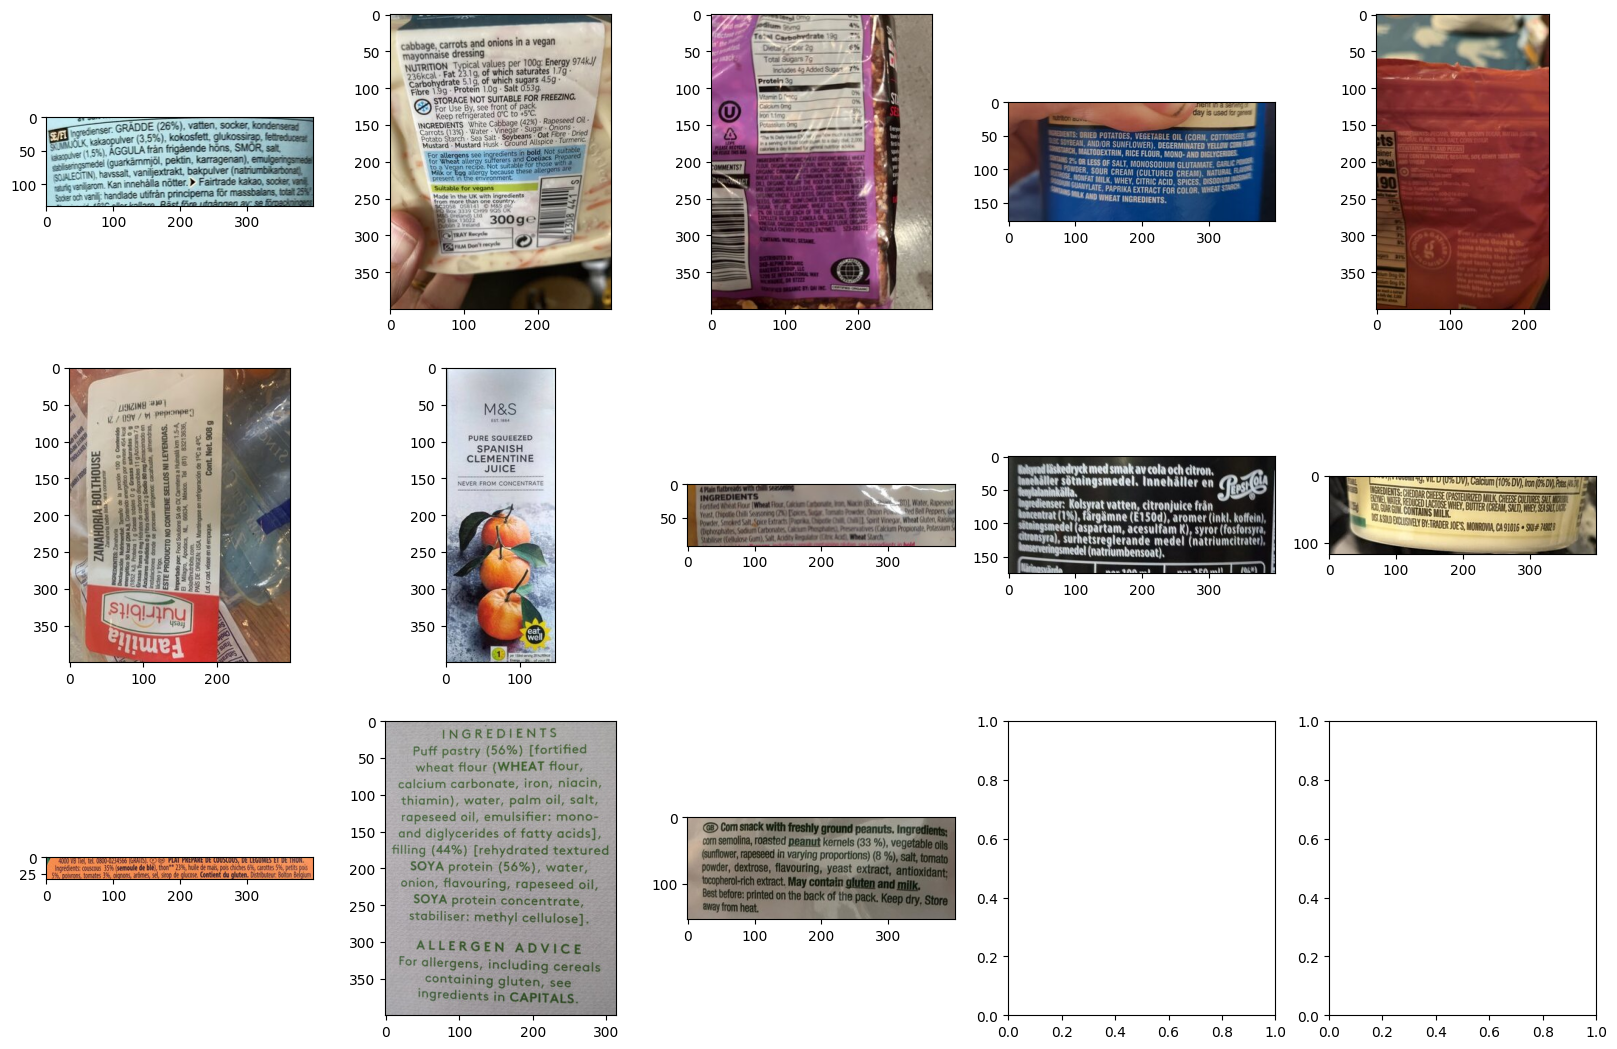

In [16]:
import matplotlib.pyplot as plt                                  # plotting library

zero = ingr_test[ingr_test["recall"] <= 0.05].index              # rows of the photos that scored about 0
print(len(zero), "photos near 0")                                # how many
fig, axes = plt.subplots(3, 5, figsize=(20, 13))                 # a grid of 3 x 5 picture slots
for ax, i in zip(axes.flat, zero):                               # one slot per photo
    url = test_ingr.loc[i, "ingr_url"]                           # its link (same row order as ingr_test)
    pic = Image.open(BytesIO(requests.get(url, headers=headers, timeout=10).content))  # the small 400 px copy is fine for looking
    ax.imshow(pic)                                               # draw it

In [17]:
dev_nutr = picked[picked["nutr_url"].notna()].reset_index(drop=True)  # development products with a nutrition photo
print(len(dev_nutr), "development nutrition photos")             # how many we have

def read_rows(url):                                              # nutrition photo -> list of table rows as text
    full_url = url.replace(".400.", ".full.")                    # full resolution (lesson from ingredients)
    r = requests.get(full_url, headers=headers, timeout=20)      # download
    img = Image.open(BytesIO(r.content)).convert("RGB")          # bytes -> picture
    boxes = reader.readtext(np.array(img), detail=1, paragraph=False)  # detail=1: each word WITH its position
    items = []                                                   # (y-centre, x-left, height, text) per word
    for box, text, conf in boxes:                                # box = 4 corner points, conf = confidence
        ys = [p[1] for p in box]                                 # the 4 y-coordinates
        xs = [p[0] for p in box]                                 # the 4 x-coordinates
        items.append(((min(ys) + max(ys)) / 2, min(xs), max(ys) - min(ys), text))  # centre height, left edge, height, text
    if not items:                                                # nothing read at all
        return []                                                # no rows
    items.sort()                                                 # sort top to bottom (by y-centre)
    gap = np.median([h for _, _, h, _ in items]) / 2             # words closer than half a text height = same row
    rows, current = [], [items[0]]                               # finished rows; row being built
    for it in items[1:]:                                         # go through the remaining words
        if it[0] - current[-1][0] < gap:                         # close in height to the previous word?
            current.append(it)                                   # same row
        else:                                                    # clearly lower down
            rows.append(current)                                 # finish the row
            current = [it]                                       # start a new one
    rows.append(current)                                         # finish the last row
    return [" | ".join(t for _, _, _, t in sorted(row, key=lambda w: w[1])) for row in rows]  # each row: words left to right

prod = dev_nutr.loc[0]                                           # first product with a nutrition photo
for line in read_rows(prod["nutr_url"]):                         # print its rows
    print(line)                                                  # e.g. "Protein | 8.2g | 3.3g"
print("OFF:", prod["product_name"], "| protein", prod["protein_g"], "fat", prod["fat_g"],
      "carbs", prod["carb_g"], "sugars", prod["sugars_g"], "fibre", prod["fiber_g"], "sodium", prod["sodium_g"])  # the correct values

49 development nutrition photos
Nutriton | Facts
about 20 servings per container
Serving size | 2 cookies (29g)
Amount per serving
Calories | 140
% Daily Value*
Total Fat Tg_ | 9%
Saturated Fat 2g | 10%
Trans Fat Og
Cholesterol | Omg | 0%
Sodium | 75mg | 3%
Total Carbohydrate 20g | 7%
Dietary Fiber Og_ | 0%
Total Sugars 12g
Includes 12g Added Sugars | 24%
Protein less than 1g
Vitamin D Omcg _
Calcium Omg_ | 0%
Iron 0.Smg | 2%
Potassium 1Omg | %
The % Daily Value (DV) tells you how much a
nutrient in a | daily diet. 2,000 | Oovin?ooief | of food contributes t0 & | a day is used for
general nutrition advice.
IGREDIENTS: SUGAR,UNBLEACHED ENRICHED FlouR (VHEAT
FLOUR, NIACIN   REDUCED  IRON | Tn tolcocoita
MiarM EuRIBOEAvMa WeruotoSz" Couc ScID5 P4
Hdion Caoln oicrGn RRVoTOSEFCorR SYa4i Sc1D;,
Bakng Soda Coy LEcitttd EXtuaCH (EgeoABLeColor}, | ARTIFICiAl FLAVOR; ANNATTO
OFF: Lemon creme sandwich cookies | protein 3.45 fat 24.14 carbs 68.97 sugars 41.38 fibre 0.0 sodium 0.26276


In [18]:
def fix_ocr(t):                                                  # repair typical OCR slips around numbers
    t = t.replace("_", " ")                                      # NEW: "Tg_" -> "Tg " (underscore blocks the unit match)
    t = re.sub(r"\bO(?=\s?m?g\b)", "0", t)                       # "Og" / "Omg" -> "0g" / "0mg" (letter O before a unit)
    t = re.sub(r"\bT(?=g)", "7", t)                              # "Tg" -> "7g"
    t = re.sub(r"(?<=\d\.)S", "5", t)                            # "0.Smg" -> "0.5mg"
    return t.replace(",", ".")                                   # European decimal comma "3,5" -> "3.5"

def first_amount(row):                                           # first "number + unit" in a row, in grams
    m = re.search(r"(\d+(?:\.\d+)?)\s*(mg|g)\b", row)            # e.g. "75mg" or "20 g"
    if not m:                                                    # no amount in this row
        return None                                              # nothing found
    value = float(m.group(1))                                    # the number
    return value / 1000 if m.group(2) == "mg" else value         # mg -> g

def find_row(rows, must, avoid=()):                              # first row containing a word in `must` and none in `avoid`
    for row in rows:                                             # top to bottom
        low = row.lower()                                        # compare in lowercase
        if any(w in low for w in must) and not any(w in low for w in avoid):  # matches?
            return row                                           # found
    return None                                                  # not found

def parse_panel(rows):                                           # table rows -> nutrients per 100 g
    rows = [fix_ocr(r) for r in rows]                            # repair OCR slips first
    text = " ".join(rows).lower()                                # everything as one string, for searching
    per100 = re.search(r"100\s?(g|ml)", text) is not None        # does the label mention per 100 g/ml?
    factor = 1.0                                                 # numbers are already per 100 g
    if not per100:                                               # US-style label (per serving)
        m = re.search(r"serving size[^(]*\((\d+(?:\.\d+)?)\s*(g|ml)\)", text)  # serving size in brackets, e.g. "(29g)"
        if not m:                                                # no serving size found
            return {}                                            # cannot convert: give up on this photo
        factor = 100 / float(m.group(1))                         # e.g. 100 / 29

    targets = {                                                  # nutrient -> (row words, words to avoid)
        "protein_g": (["protein"], []),
        "fat_g":     (["fat"], ["saturat", "trans", "mono", "poly"]),
        "carb_g":    (["carbohydrate", "carbs"], []),
        "sugars_g":  (["sugar"], ["added", "alcohol"]),
        "fiber_g":   (["fibre", "fiber"], []),
        "sodium_g":  (["sodium"], []),
    }
    found = {}                                                   # results
    for name, (must, avoid) in targets.items():                  # each nutrient
        row = find_row(rows, must, avoid)                        # its row
        amount = first_amount(row) if row else None              # its first amount
        if amount is not None:                                   # found something
            found[name] = round(amount * factor, 3)              # convert to per 100 g
    if "sodium_g" not in found:                                  # no sodium row (UK/EU style)?
        row = find_row(rows, ["salt"])                           # look for salt
        amount = first_amount(row) if row else None              # its amount
        if amount is not None:                                   # found
            found["sodium_g"] = round(amount * factor / 2.5, 3)  # salt -> sodium
    return found                                                 # e.g. {"protein_g": 3.45, ...}

rows0 = read_rows(prod["nutr_url"])                              # the cookie panel again
print(parse_panel(rows0))                                        # parsed values

{'protein_g': 3.448, 'fat_g': 24.138, 'carb_g': 68.966, 'sugars_g': 41.379, 'fiber_g': 0.0, 'sodium_g': 0.259}


Lemon creme sandwich cookies


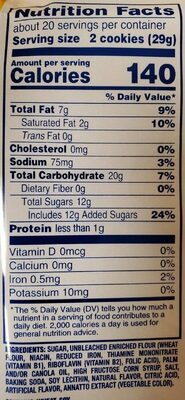

In [19]:
r = requests.get(prod["nutr_url"], headers=headers, timeout=10)  # download the photo (400 px copy is fine for looking)
pic = Image.open(BytesIO(r.content))                             # bytes -> picture
print(prod["product_name"])                                      # which product
pic                                                              # last line on its own = show it

In [20]:
nutrients = ["protein_g", "fat_g", "carb_g", "sugars_g", "fiber_g", "sodium_g"]  # the six we score

def is_close(pred, true, name):                                  # our fixed scoring rule
    floor = 0.05 if name == "sodium_g" else 0.5                  # smallest allowed error (sodium values are small)
    return abs(pred - true) <= max(0.2 * true, floor)            # within 20% or the floor, whichever is larger

records = []                                                     # one entry per (product, nutrient)
for i, prod in dev_nutr.iterrows():                              # each development nutrition photo
    try:                                                         # safety net
        parsed = parse_panel(read_rows(prod["nutr_url"]))        # OCR + parser
    except Exception:                                            # download/reading problem
        parsed = {}                                              # treat as nothing found
    for name in nutrients:                                       # each nutrient
        true = prod[name]                                        # OFF's value (the answer key)
        pred = parsed.get(name)                                  # parser's value, or None
        records.append({"code": prod["code"], "product_name": prod["product_name"], "nutrient": name,
                        "true": true, "pred": pred,
                        "found": pred is not None,               # did the parser find it?
                        "correct": pred is not None and pd.notna(true) and is_close(pred, true, name)})  # and is it right?
    print(i, str(prod["product_name"])[:30], parsed)             # progress: what was parsed

nutr_dev = pd.DataFrame(records)                                 # list -> table
nutr_dev = nutr_dev[nutr_dev["true"].notna()]                    # skip nutrients OFF has no value for (rule fixed now)
nutr_dev.to_csv("ocr_nutrition_dev.csv", index=False)            # save
print(nutr_dev.groupby("nutrient")[["found", "correct"]].mean().round(2))  # per nutrient: share found, share correct
print("overall correct:", round(nutr_dev["correct"].mean(), 2))  # one summary number

0 Lemon creme sandwich cookies {'protein_g': 3.448, 'fat_g': 24.138, 'carb_g': 68.966, 'sugars_g': 41.379, 'fiber_g': 0.0, 'sodium_g': 0.259}
1 Sausage Roll 100% British Pork {}
2 Raw Brazil Nuts {}
3 Fairtrade Unrefined Demerara P {}
4 British Red Leicester {}
5 TIRAMISU FLAVOUR {}
6 Peppered Hot Smoked Salmon Fil {}
7 coconut macaroons {}
8 Sliced Green Jalapeño Peppers {'protein_g': 1.1, 'sugars_g': 0.4, 'fiber_g': 2.2, 'sodium_g': 1.2}
9 Extra Virgin Olive Oil {}
10 Wheat & Rye Sourdough Bread {}
11 Crispy M&Ms {'protein_g': 57.0, 'carb_g': 14.0, 'sugars_g': 57.0, 'sodium_g': 1.68}
12 Hickory & Oak Wood Scottish Sm {'protein_g': 26.0, 'fat_g': 70.0, 'carb_g': 1.7, 'sugars_g': 90.0, 'fiber_g': 0.5, 'sodium_g': 1.232}
13 Cherry & amaretto stollen slic {'protein_g': 5.7, 'fat_g': 17.4, 'carb_g': 52.5, 'sugars_g': 30.7, 'fiber_g': 2.5, 'sodium_g': 0.104}
14 Whole grain health bread {}
15 Halved Brussels Sprouts, Butte {'fat_g': 0.0, 'carb_g': 0.015, 'fiber_g': 3.093, 'sodium_g': 0.015}

In [21]:
for i in [1, 4, 14]:                                             # sausage roll, Red Leicester, porridge oats (all came back {})
    prod = dev_nutr.loc[i]                                       # that product
    print("=====", prod["product_name"])                         # header
    try:                                                         # catch errors, but this time SHOW them
        rows = read_rows(prod["nutr_url"])                       # OCR rows
        text = " ".join(fix_ocr(r) for r in rows).lower()        # same text the parser searches
        print("rows read:", len(rows), "| per-100 found:", re.search(r"100\s?(g|ml)", text) is not None)  # the key check
        for line in rows[:15]:                                   # first 15 rows
            print("   ", line)                                   # show them
    except Exception as e:                                       # an error happened
        print("ERROR:", repr(e))                                 # show exactly what it was

===== Sausage Roll 100% British Pork
rows read: 36 | per-100 found: False
    4
    pastry: | encosed
    This | Roll | Contoins
    48Okcai | 1995kJ | Energy | 34.90 | Fat | Saturates | 14.90 | Sugars | 12g | 1.42g | Salt
    240 | 500/0 | 750/ | 100 | 2400
    o the reference intake
    Typical | values per 1QOp; Energy 15340u/389kcaL
    Nutritional Information
    Per 10Og Energy 1534k4/369kcal;
    Fot 26.8g,Saturates 115g,
    carbohyarate 21.89,Sugars,0.99
    Fibre 1.6g, Protein 93g, Salt 109g
    "Reference intake of an average
    adult (840kJ/zoookcal):
    Reheating Guidelines
===== British Red Leicester
rows read: 16 | per-100 found: False
    NUTRITION  | This pack contansappuok T3 servngs =
    tpICAL Values | Per 10Og  | Per serving BOg}
    Energy  | 7670k8/403kcal | S0TkfT2Ikal
    Fat | 33.6g | 1O.1g
    ofwhich saturates  | ZL.10 | 63g
    (arbohydrate  | O1g
    ofwhich sugars | O.1g | 8
    Fbre | Ug
    Protei | 25.0g | 730
    Sakt | obg | 00
    BEST BEFORE: Se

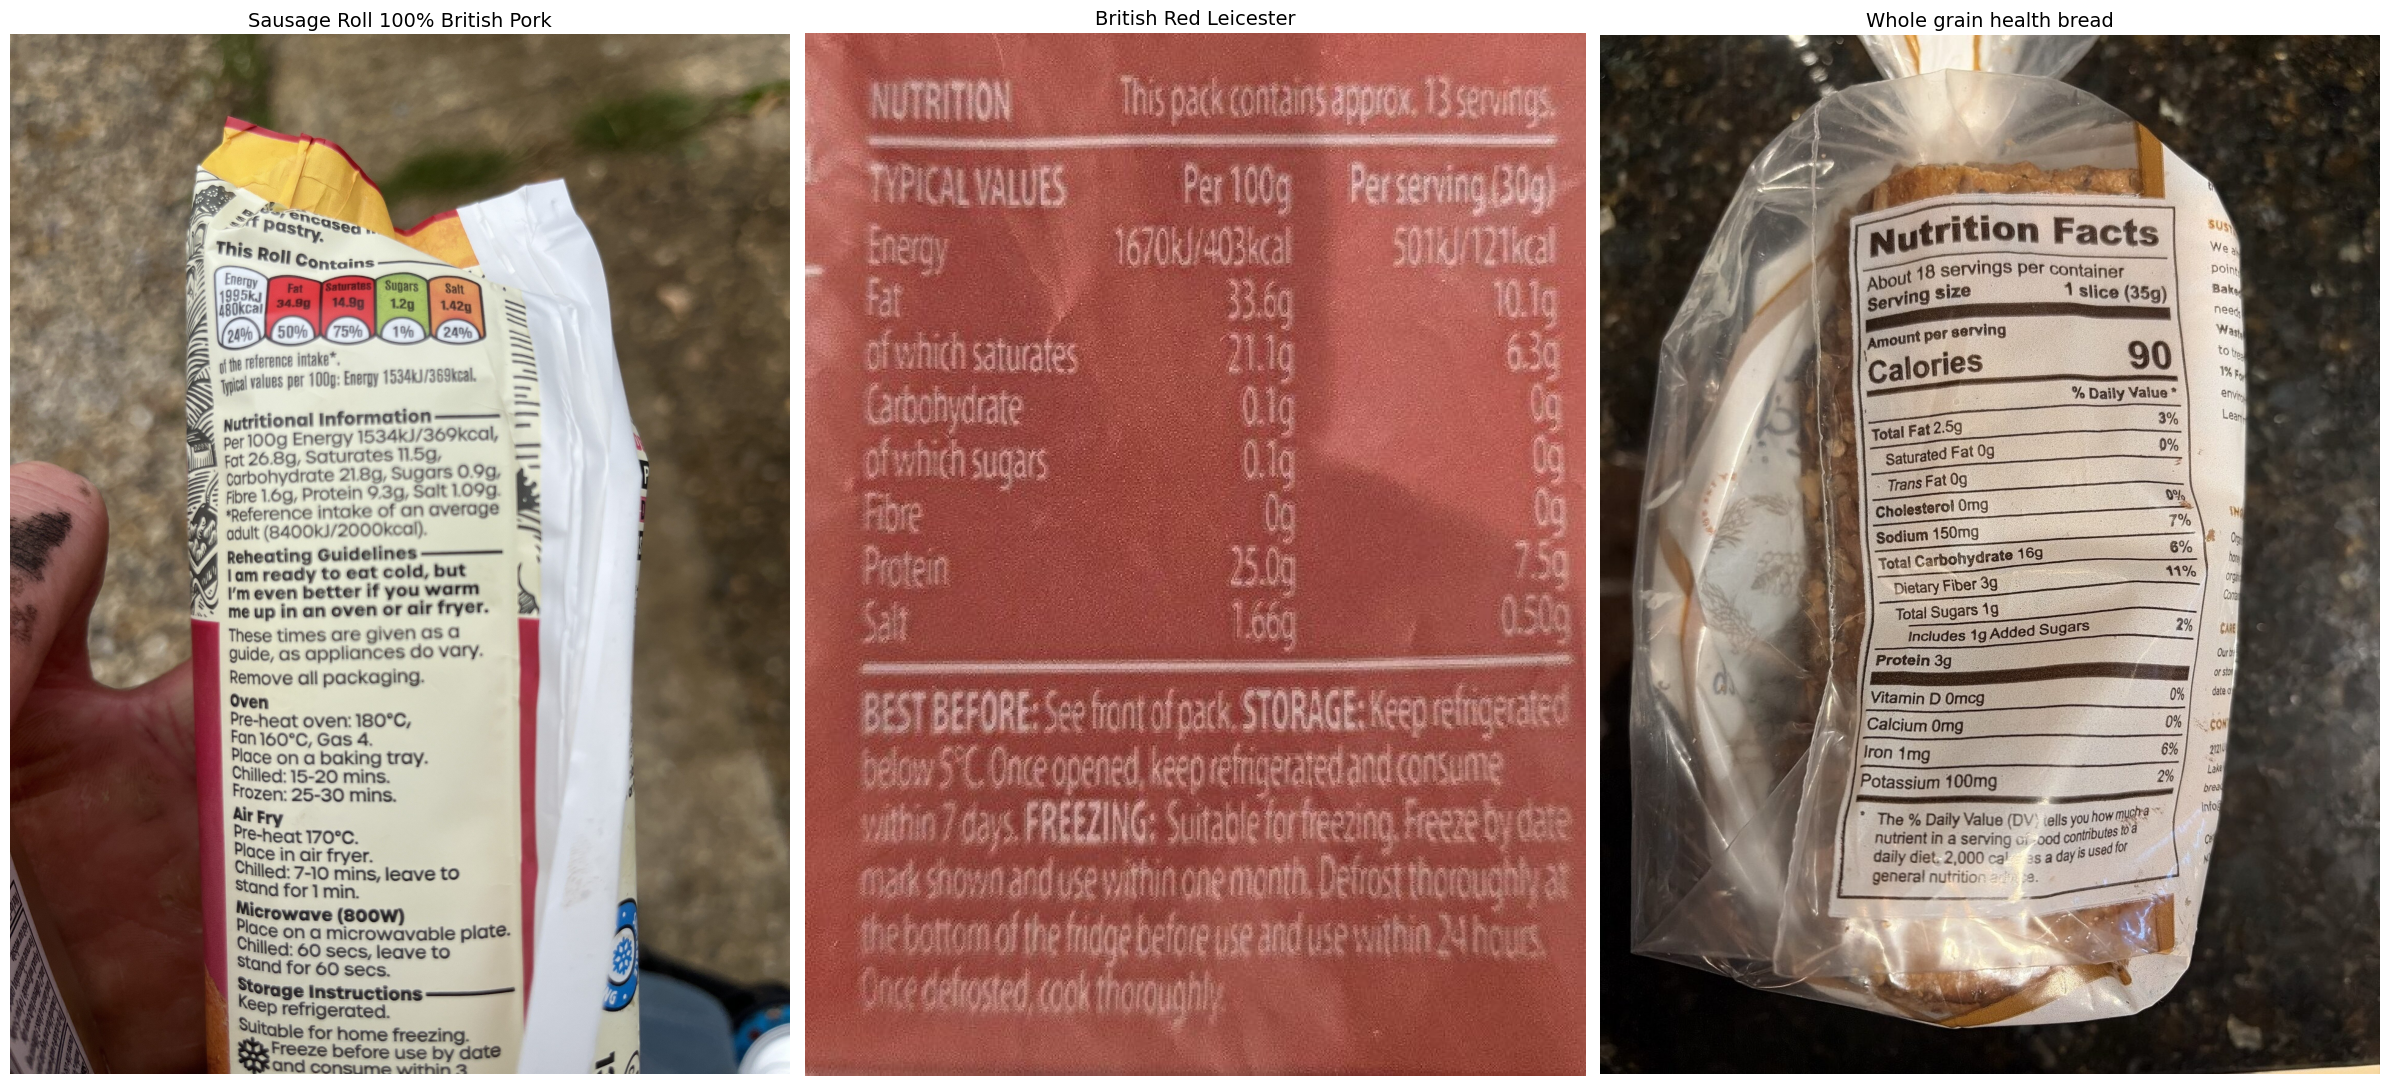

In [22]:
import matplotlib.pyplot as plt                                  # plotting

fig, axes = plt.subplots(1, 3, figsize=(24, 12))                 # three photos side by side, big enough to read
for ax, i in zip(axes, [1, 4, 14]):                              # the same three products
    prod = dev_nutr.loc[i]                                       # that product
    url = prod["nutr_url"].replace(".400.", ".full.")            # full-resolution photo
    pic = Image.open(BytesIO(requests.get(url, headers=headers, timeout=20).content))  # download -> picture
    ax.imshow(pic)                                               # draw it
    ax.set_title(str(prod["product_name"])[:40], fontsize=14)    # product name
    ax.axis("off")                                               # no axes
plt.tight_layout()                                               # tidy spacing
plt.show()                                                       # display

In [23]:
rows_cache = {}                                                  # product row number -> list of table rows
for i, prod in dev_nutr.iterrows():                              # each development nutrition photo
    try:                                                         # safety net...
        rows_cache[i] = read_rows(prod["nutr_url"])              # OCR -> rows, stored
    except Exception as e:                                       # ...but now we SAY what went wrong
        rows_cache[i] = []                                       # empty rows
        print(i, "ERROR:", repr(e))                              # show the error
print(len(rows_cache), "photos read")                            # should be 36

49 photos read


In [24]:
from rapidfuzz import fuzz                                       # approximate word matching

def fix_ocr_v2(t):                                               # repair OCR slips around numbers (v2)
    t = t.replace("_", " ")                                      # underscores block the unit match
    t = re.sub(r"\b[OU](?=\s?m?g\b)", "0", t)                    # "Og", "Ug", "Omg" -> "0g", "0mg"
    t = re.sub(r"\bT(?=g)", "7", t)                              # "Tg" -> "7g"
    t = re.sub(r"(?<=\d\.)S", "5", t)                            # "0.Smg" -> "0.5mg"
    t = re.sub(r"\b1[0OoQq]{2}\s?[gG9]\b", "100g", t)            # NEW: "10Og", "1Q0g" -> "100g"
    return t.replace(",", ".")                                   # decimal comma -> point

def find_row_v2(rows, must, avoid=()):                           # first row with a word CLOSE to a `must` word (v2)
    for row in rows:                                             # top to bottom
        ws = re.findall(r"[a-z]+", row.lower())                  # the row's words, letters only
        if any(w.startswith(a) for w in ws for a in avoid):      # contains a word to avoid?
            continue                                             # skip this row
        if any(fuzz.ratio(w, m) >= 75 for w in ws for m in must):  # NEW: "Protei" ~ "protein", "Sakt" ~ "salt"
            return row                                           # found
    return None                                                  # not found

def parse_panel_v2(rows):                                        # rows -> nutrients per 100 g (v2)
    rows = [fix_ocr_v2(r) for r in rows]                         # repair OCR slips
    text = " ".join(rows).lower()                                # one string for searching
    factor = 1.0                                                 # NEW default: assume per 100 g
    if not re.search(r"100\s?(g|ml)", text):                     # no per-100 column found...
        m = re.search(r"serving size[^(]*\((\d+(?:\.\d+)?)\s*(g|ml)\)", text)  # ...look for a US serving size
        if m:                                                    # US label
            factor = 100 / float(m.group(1))                     # per serving -> per 100 g
    targets = {                                                  # nutrient -> (label words, words to avoid)
        "protein_g": (["protein"], []),
        "fat_g":     (["fat"], ["saturat", "trans", "mono", "poly"]),
        "carb_g":    (["carbohydrate", "carbohydrates", "carbs"], []),
        "sugars_g":  (["sugar", "sugars"], ["added", "alcohol"]),
        "fiber_g":   (["fibre", "fiber"], []),
        "sodium_g":  (["sodium"], []),
    }
    found = {}                                                   # results
    for name, (must, avoid) in targets.items():                  # each nutrient
        row = find_row_v2(rows, must, avoid)                     # its row
        amount = first_amount(row) if row else None              # first amount (same function as v1)
        if amount is not None and amount * factor <= 100:        # NEW: reject impossible values
            found[name] = round(amount * factor, 3)              # store
    if "sodium_g" not in found:                                  # no sodium row: use salt
        row = find_row_v2(rows, ["salt"])                        # salt row
        amount = first_amount(row) if row else None              # its amount
        if amount is not None and amount * factor <= 100:        # plausible?
            found["sodium_g"] = round(amount * factor / 2.5, 3)  # salt -> sodium
    return found                                                 # dictionary

In [25]:
def score(parser):                                               # parser function -> results table
    records = []                                                 # one entry per (product, nutrient)
    for i, prod in dev_nutr.iterrows():                          # each product
        parsed = parser(rows_cache[i])                           # parse the stored rows (no new OCR)
        for name in nutrients:                                   # each nutrient
            true, pred = prod[name], parsed.get(name)            # answer key and parser value
            if pd.isna(true):                                    # OFF has no value
                continue                                         # skip (rule fixed earlier)
            records.append({"i": i, "product_name": prod["product_name"], "nutrient": name, "true": true, "pred": pred,
                            "found": pred is not None,
                            "correct": pred is not None and is_close(pred, true, name)})
    return pd.DataFrame(records)                                 # list -> table

for label, parser in [("v1", parse_panel), ("v2", parse_panel_v2)]:  # compare both versions
    res = score(parser)                                          # score it
    print(label, "found:", round(res["found"].mean(), 2), "| correct:", round(res["correct"].mean(), 2))  # summary
nutr_dev_v2 = score(parse_panel_v2)                              # keep v2's detailed results
print(nutr_dev_v2.groupby("nutrient")[["found", "correct"]].mean().round(2))  # v2 per nutrient

v1 found: 0.21 | correct: 0.18
v2 found: 0.51 | correct: 0.3
           found  correct
nutrient                 
carb_g      0.59     0.35
fat_g       0.27     0.16
fiber_g     0.57     0.35
protein_g   0.57     0.33
sodium_g    0.59     0.35
sugars_g    0.49     0.24


In [26]:
wrong = nutr_dev_v2[nutr_dev_v2["found"] & ~nutr_dev_v2["correct"]]  # found a value, but not within tolerance (~ = "not")
print(len(wrong), "wrong values")                                # how many
print((wrong["pred"] / wrong["true"]).round(2).describe())       # ratio parser / OFF: ~10 = dropped decimal; ~0.3 = serving column?
for _, w in wrong.head(15).iterrows():                           # first 15 examples
    row = find_row_v2([fix_ocr_v2(r) for r in rows_cache[w["i"]]],  # the row the parser used...
                      *{"protein_g": (["protein"], []),
                        "fat_g": (["fat"], ["saturat", "trans", "mono", "poly"]),
                        "carb_g": (["carbohydrate", "carbohydrates", "carbs"], []),
                        "sugars_g": (["sugar", "sugars"], ["added", "alcohol"]),
                        "fiber_g": (["fibre", "fiber"], []),
                        "sodium_g": (["sodium"], [])}[w["nutrient"]])  # ...found again with the same rules
    print(f'{str(w["product_name"])[:25]:25} {w["nutrient"]:9} OFF {w["true"]:7.2f} parser {w["pred"]:7.2f} | row: {row}')

64 wrong values
count    64.0000
mean         inf
std          NaN
min       0.0000
25%       0.1975
50%       0.4000
75%      10.0000
max          inf
dtype: float64
Sausage Roll 100% British protein_g OFF    9.30 parser    1.60 | row: Fibre 1.6g. Protein 93g. Salt 109g
Sausage Roll 100% British sugars_g  OFF    0.90 parser   12.00 | row: 48Okcai | 1995kJ | Energy | 34.90 | Fat | Saturates | 14.90 | Sugars | 12g | 1.42g | Salt
Sausage Roll 100% British sodium_g  OFF    1.09 parser    4.80 | row: None
Raw Brazil Nuts           protein_g OFF   13.33 parser    2.00 | row: cremeuses tout en | NOIX DU BRESIL | gout riche et plus de | comme | Les noix du | VOS recettes de | collation | Bresil | saine | cuisine | dues | etant | texture Qu | biologiques . | classique pour leur | une | delicieuse: | source | savourez-les | de fibres Ajoutez-les | Elan | sont | donner un | legerement | sur le pouce | Protein | Carbohydrate | Sugars | Fibre | Trans | Fibres 2 g | Proteines 4 9 | Sucres 1g | tran

In [27]:
def fix_ocr_v3(t):                                               # v2 repairs + two decimal-point repairs
    t = fix_ocr_v2(t)                                            # everything v2 already does
    t = re.sub(r"\b0(\d)(?=\s?m?g\b)", r"0.\1", t)               # NEW: "01g" -> "0.1g" (a leading 0 must be "0.")
    t = re.sub(r"\b(\d{1,2}) (\d)(?=\s?m?g\b)", r"\1.\2", t)     # NEW: "24 6g" -> "24.6g" (decimal read as a space)
    return t

def find_label(rows, must, avoid=()):                            # like find_row, but returns the row FROM the label onward
    for row in rows:                                             # top to bottom
        low = row.lower()                                        # lowercase copy
        ws = re.findall(r"[a-z]+", low)                          # the row's words
        if any(w.startswith(a) for w in ws for a in avoid):      # contains a word to avoid?
            continue                                             # skip
        for m in re.finditer(r"[a-z]+", low):                    # each word, with its position in the row
            if any(fuzz.ratio(m.group(), k) >= 75 for k in must):  # close to a label word?
                return row[m.start():]                           # NEW: text from the label onward ("Protein 93g. Salt 109g")
    return None                                                  # not found

def parse_panel_v3(rows):                                        # rows -> nutrients per 100 g (v3)
    rows = [fix_ocr_v3(r) for r in rows]                         # repairs
    text = " ".join(rows).lower()                                # one string
    factor = 1.0                                                 # default per 100 g
    if not re.search(r"100\s?(g|ml)", text):                     # no per-100 column
        m = re.search(r"serving size.*?(\d+(?:\.\d+)?)\s*(g|ml)\b", text)  # NEW: "(29g)" OR "28g", anywhere after "serving size"
        if m and float(m.group(1)) > 0:                                                  # US label
            factor = 100 / float(m.group(1))                     # per serving -> per 100 g
    targets = {                                                  # same labels as v2
        "protein_g": (["protein"], []),
        "fat_g":     (["fat"], ["saturat", "trans", "mono", "poly"]),
        "carb_g":    (["carbohydrate", "carbohydrates", "carbs"], []),
        "sugars_g":  (["sugar", "sugars"], ["added", "alcohol"]),
        "fiber_g":   (["fibre", "fiber"], []),
        "sodium_g":  (["sodium"], []),
    }
    found = {}                                                   # results
    for name, (must, avoid) in targets.items():                  # each nutrient
        part = find_label(rows, must, avoid)                     # row text from the label onward
        amount = first_amount(part) if part else None            # first amount AFTER the label
        if amount is not None and amount * factor <= 100:        # plausible
            found[name] = round(amount * factor, 3)              # store
    if "sodium_g" not in found:                                  # no sodium: use salt
        part = find_label(rows, ["salt"])                        # salt, from the label onward
        amount = first_amount(part) if part else None            # its amount
        if amount is not None and amount * factor <= 100:        # plausible
            found["sodium_g"] = round(amount * factor / 2.5, 3)  # salt -> sodium
    return found

for label, parser in [("v1", parse_panel), ("v2", parse_panel_v2), ("v3", parse_panel_v3)]:  # compare all three
    res = score(parser)                                          # score on stored rows
    print(label, "found:", round(res["found"].mean(), 2), "| correct:", round(res["correct"].mean(), 2))
nutr_dev_v3 = score(parse_panel_v3)                              # keep v3's details
print(nutr_dev_v3.groupby("nutrient")[["found", "correct"]].mean().round(2))  # per nutrient

v1 found: 0.21 | correct: 0.18
v2 found: 0.51 | correct: 0.3
v3 found: 0.5 | correct: 0.32
           found  correct
nutrient                 
carb_g      0.59     0.41
fat_g       0.27     0.18
fiber_g     0.53     0.37
protein_g   0.59     0.39
sodium_g    0.51     0.29
sugars_g    0.49     0.27


In [28]:
test_nutr = test_picked[test_picked["nutr_url"].notna()].reset_index(drop=True)  # test products with a nutrition photo
print(len(test_nutr), "test nutrition photos")                   # how many

test_rows = {}                                                   # OCR rows for the test photos
for i, prod in test_nutr.iterrows():                             # each test photo
    try:                                                         # safety net
        test_rows[i] = read_rows(prod["nutr_url"])               # OCR -> rows
    except Exception as e:                                       # show errors
        test_rows[i] = []                                        # empty
        print(i, "ERROR:", repr(e))                              # what went wrong

records = []                                                     # one entry per (product, nutrient)
for i, prod in test_nutr.iterrows():                             # each test product
    parsed = parse_panel_v3(test_rows[i])                        # FROZEN v3 parser
    for name in nutrients:                                       # each nutrient
        true, pred = prod[name], parsed.get(name)                # answer key, parser value
        if pd.isna(true):                                        # OFF has no value
            continue                                             # skip (same rule)
        records.append({"code": prod["code"], "product_name": prod["product_name"], "nutrient": name,
                        "true": true, "pred": pred, "found": pred is not None,
                        "correct": pred is not None and is_close(pred, true, name)})
nutr_test = pd.DataFrame(records)                                # list -> table
nutr_test.to_csv("ocr_nutrition_test.csv", index=False)          # save
print("TEST found:", round(nutr_test["found"].mean(), 2), "| correct:", round(nutr_test["correct"].mean(), 2))  # headline
print(nutr_test.groupby("nutrient")[["found", "correct"]].mean().round(2))  # per nutrient

151 test nutrition photos
TEST found: 0.47 | correct: 0.25
           found  correct
nutrient                 
carb_g      0.51     0.21
fat_g       0.19     0.17
fiber_g     0.54     0.33
protein_g   0.51     0.23
sodium_g    0.61     0.31
sugars_g    0.47     0.23


In [29]:
records = []                                                     # one entry per (product, nutrient)
for i, prod in test_nutr.iterrows():                             # each test product
    parsed = parse_panel_v3(test_rows[i])                        # frozen v3 (+ divide-by-zero guard)
    for name in nutrients:                                       # each nutrient
        true, pred = prod[name], parsed.get(name)                # answer key, parser value
        if pd.isna(true):                                        # OFF has no value
            continue                                             # skip (same rule)
        records.append({"code": prod["code"], "product_name": prod["product_name"], "nutrient": name,
                        "true": true, "pred": pred, "found": pred is not None,
                        "correct": pred is not None and is_close(pred, true, name)})
nutr_test = pd.DataFrame(records)                                # list -> table
nutr_test.to_csv("ocr_nutrition_test.csv", index=False)          # save
print("TEST found:", round(nutr_test["found"].mean(), 2), "| correct:", round(nutr_test["correct"].mean(), 2))  # headline
print(nutr_test.groupby("nutrient")[["found", "correct"]].mean().round(2))  # per nutrient|

TEST found: 0.47 | correct: 0.25
           found  correct
nutrient                 
carb_g      0.51     0.21
fat_g       0.19     0.17
fiber_g     0.54     0.33
protein_g   0.51     0.23
sodium_g    0.61     0.31
sugars_g    0.47     0.23


In [30]:
dev_nutr.to_csv("dev_nutr.csv", index=False)                     # the 36 development products (links + OFF's correct values)
test_nutr.to_csv("test_nutr.csv", index=False)                   # the test products (same photos the v3 parser was scored on)
print(len(dev_nutr), len(test_nutr))                             # check the counts

49 151
